# RQ4 pipeline, step 3: k-means and Louvain groups in listening-embedding space

## Question
`RQ4_extension/02` compared each track's **sound** (audio embedding) with its **listening** profile (an item2vec vector learned from which tracks are played in the same sessions, without audio). It found that sound predicts a large part of listening, that the strongest shared directions are the differences between k-means pseudo-genres,
that every pseudo-genre is cohesive in listening space, but that clustering the listening vectors gives a different partition from the pseudo-genres.

This notebook repeats the parts of that analysis that depend on the **choice of sound partition**, with Louvain groups next to k-means:
1. **Cohesion:** are the tracks of one Louvain group closer in listening space than random tracks, and more or less so than for k-means pseudo-genres? (with artist and album controls)
2. **Shared directions:** do the directions shared by sound and listening (CCA) line up with Louvain groups as much as with pseudo-genres?
3. **Partitions from listening:** we cluster the listening vectors (k-means, and Louvain on a kNN graph of the listening vectors) and ask which sound partition is closer to them.
4. **Organic versus recommended:** does the stream difference found in `RQ4_extension/02` (recommended listening follows sound more closely) also hold with Louvain groups?

The parts of `RQ4_extension/02` that do not involve any partition (canonical correlations, R² of listening from sound, popularity checks, the unseen-artist split) do not change and are not repeated.

| § | Content |
|---|---|
| 1 | Data: the saved listening embeddings and the partitions |
| 2 | Cohesion in listening space |
| 3 | Shared sound-listening directions by partition |
| 4 | Partitions found from listening |
| 5 | Organic versus recommended |
| 6 | Summary |

*Prerequisites:* the listening embeddings saved by `RQ4_extension/02` (`data/processed/listening_emb_*.npy`; organic and recommended streams, shared stream rule, equal training tokens), `RQ4_pipeline/louvain_groups.csv.gz`, the artist and album mappings. Run time: about 3 minutes. Memory: about 2 GB.

## 0. Setup and parameters

In [1]:
import sys
import time
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- parameters (change here, then Run All) ----------------
N_SEEDS = 3; N_FIT = 150_000
CCA_REG = 1e-2; TEST_FRAC = 0.2; NC = 10           # CCA settings of RQ4_extension/02
K_LISTEN_NN = 20                                    # neighbours for Louvain on the listening vectors
SEED = 42

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REAL, NULL, ACC, KM = "#264653", "#9aa0a6", "#e76f51", "#e9c46a"
COL = {"organic": "#2a9d8f", "recommended": "#e76f51"}

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import louvain as LV
from rq4_tools import spherical_kmeans, kmeans_grid, nmi, effective_number
DATA, PROC, OUT = ROOT / "data" / "raw" / "yambda", ROOT / "data" / "processed", ROOT / "RQ4_pipeline"
ari = LV.adjusted_rand_index
print("project root:", ROOT)

project root: C:\MSc DTU\Semester 3\01. CTDS\Music


## 1. Data and partitions
The listening embeddings are the raw item2vec vectors saved by `RQ4_extension/02` for the 19,962 tracks that have an audio embedding and a listening vector in **both** streams (at least 20 plays each). As there, they are centred and scaled to unit length, with no direction removed.

Partitions of these tracks: Louvain (five seeds), the project's k-means file (k = 32), and k-means with k = 32 and with k = the number of Louvain groups (three starts each, fitted on 150,000 random tracks as in `RQ4_extension`).

In [2]:
t0 = time.time()
common = np.load(PROC / "listening_emb_item_ids.npy")
def unit(Z): return Z / np.maximum(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12)
Y = {n: unit(np.load(PROC / f"listening_emb_{n}_raw.npy").astype(np.float64) - np.load(PROC / f"listening_emb_{n}_raw.npy").astype(np.float64).mean(0)) for n in ["organic", "recommended"]}
emb_ids = np.load(PROC / "emb50m_item_ids.npy"); L = int(max(emb_ids.max(), common.max())) + 1
item_row = np.full(L, -1, dtype=np.int64); item_row[emb_ids] = np.arange(len(emb_ids)); rows_c = item_row[common]; assert (rows_c >= 0).all()
EN = np.load(PROC / "emb50m_norm.npy"); Xa = EN[rows_c].astype(np.float64)

grp = pd.read_csv(OUT / "louvain_groups.csv.gz"); assert np.array_equal(grp["item_id"].to_numpy(), emb_ids)
LSEEDS = [int(c.split("_s")[1]) for c in grp.columns if c.startswith("louvain_s")]
K_MATCH = int(grp.loc[grp.in_graph, "louvain_s0"].max()) + 1
km = kmeans_grid(EN, [32, K_MATCH], N_SEEDS, N_FIT, SEED); del EN
km_file = pd.read_csv(ROOT / "RQ4_kmeans/kmeans_pseudogenres_k32.csv.gz").set_index("item_id")["kmeans_cluster"].reindex(emb_ids).to_numpy()
relab = lambda v: np.unique(v, return_inverse=True)[1]
PARTS = {f"Louvain ({K_MATCH} groups)": [relab(grp[f"louvain_s{s}"].to_numpy()[rows_c]) for s in LSEEDS],
         "k-means project file (k = 32)": [relab(km_file[rows_c])],
         f"k-means, k = {K_MATCH}": [relab(km[(K_MATCH, s)][rows_c]) for s in range(N_SEEDS)],
         "k-means, k = 32": [relab(km[(32, s)][rows_c]) for s in range(N_SEEDS)]}
PCOL = dict(zip(PARTS, [ACC, KM, "#bc8a00", REAL]))
mp = lambda path, col: pd.read_parquet(path).drop_duplicates("item_id").set_index("item_id")[col].reindex(common).fillna(-1).astype(np.int64).to_numpy()
art_c, alb_c = mp(DATA / "artist_item_mapping.parquet", "artist_id"), mp(DATA / "album_item_mapping.parquet", "album_id")
print(f"{len(common):,} tracks with audio and listening vectors in both streams; {grp.in_graph.to_numpy()[rows_c].mean():.0%} of them are among Louvain's 50,000 graph tracks")
print({n: f"{len(np.unique(r[0]))} groups present" for n, r in PARTS.items()}, f"({time.time() - t0:.0f} s)")

19,962 tracks with audio and listening vectors in both streams; 99% of them are among Louvain's 50,000 graph tracks
{'Louvain (28 groups)': '28 groups present', 'k-means project file (k = 32)': '32 groups present', 'k-means, k = 28': '28 groups present', 'k-means, k = 32': '32 groups present'} (27 s)


## 2. Cohesion in listening space
**Measure (as in `RQ4_extension/02`, §5.1).** For each group, the mean listening cosine of random pairs of its tracks minus that of random pairs of any tracks (the *lift*), averaged over groups weighted by size. Shuffled labels give about 0.
Pairs of the same artist, or the same artist or album, can be excluded from both the group pairs and the baseline.

**Why the number of groups matters.** Finer groups are tighter, so the lift grows with the number of groups (0.20 at k = 8 to 0.32 at k = 64 in `RQ4_extension/02`). Louvain is therefore compared with k-means at its own number of groups as well as at k = 32.

In [3]:
def pair_cos(Yu, a, b, exclude):
    ok = a != b
    if exclude in ("artist", "artist or album"): ok &= ~((art_c[a] == art_c[b]) & (art_c[a] >= 0))
    if exclude == "artist or album": ok &= ~((alb_c[a] == alb_c[b]) & (alb_c[a] >= 0))
    return np.einsum("ij,ij->i", Yu[a[ok]], Yu[b[ok]])

def cohesion(Yu, lab, exclude="none", n_pairs=6000):
    k = lab.max() + 1; lift = np.full(k, np.nan)
    a, b = rng.integers(0, len(Yu), 300_000), rng.integers(0, len(Yu), 300_000); base = pair_cos(Yu, a, b, exclude).mean()
    for c in range(k):
        idx = np.flatnonzero(lab == c)
        if len(idx) < 2: continue
        v = pair_cos(Yu, rng.choice(idx, n_pairs), rng.choice(idx, n_pairs), exclude)
        if len(v): lift[c] = v.mean() - base
    share = np.bincount(lab, minlength=k) / len(lab); ok = ~np.isnan(lift)
    return float((lift[ok] * share[ok]).sum() / share[ok].sum()), lift

Yo = Y["organic"]
rows = []
for name, runs in PARTS.items():
    for excl in ["none", "artist", "artist or album"]:
        v = [cohesion(Yo, lab, excl)[0] for lab in runs]
        rows.append(dict(partition=name, excluded=excl, lift=np.mean(v), lift_sd=np.std(v), shuffled=cohesion(Yo, rng.permutation(runs[0]), excl)[0]))
coh = pd.DataFrame(rows)
print("cohesion lift in organic listening space (mean over runs):")
print(coh.pivot(index="partition", columns="excluded", values="lift").loc[list(PARTS), ["none", "artist", "artist or album"]].to_string(float_format=lambda x: f"{x:.3f}"))
print("shuffled labels:", coh.shuffled.abs().max().round(3), "(largest absolute value)")
_, lift_L = cohesion(Yo, PARTS[f"Louvain ({K_MATCH} groups)"][0], "artist or album"); _, lift_K = cohesion(Yo, PARTS["k-means project file (k = 32)"][0], "artist or album")
print(f"groups with a positive lift (same-artist/album pairs excluded): Louvain {(lift_L > 0).sum()} of {np.isfinite(lift_L).sum()} measurable, k-means file {(lift_K > 0).sum()} of {np.isfinite(lift_K).sum()}")

cohesion lift in organic listening space (mean over runs):
excluded                       none  artist  artist or album
partition                                                   
Louvain (28 groups)           0.272   0.268            0.269
k-means project file (k = 32) 0.287   0.286            0.287
k-means, k = 28               0.284   0.281            0.281
k-means, k = 32               0.296   0.295            0.294
shuffled labels: 0.002 (largest absolute value)


groups with a positive lift (same-artist/album pairs excluded): Louvain 28 of 28 measurable, k-means file 32 of 32


### 2.1 Reading the cohesion

**Every Louvain group is cohesive in listening space, slightly less so than the k-means pseudo-genres.** Tracks of one group have more similar listening vectors than random tracks for all 28 Louvain groups and all 32 pseudo-genres (same-artist/album pairs excluded). Shuffled labels give at most 0.002.

| Partition | lift (no exclusion) | same artist excluded | same artist or album excluded |
|---|---|---|---|
| Louvain (28 groups, 5 seeds) | 0.272 | 0.268 | 0.269 |
| k-means, k = 28 (3 starts) | 0.284 | 0.281 | 0.281 |
| k-means project file, k = 32 | 0.287 | 0.286 | 0.287 |
| k-means, k = 32 (3 starts) | 0.296 | 0.295 | 0.294 |

At the same number of groups the difference is about 0.01 (0.269 against 0.281), roughly 4%. This is what the comparison in notebook 01 predicts: the lift is a *mean pairwise cosine* inside a group, which rewards compact groups around a centre (the k-means criterion, where k-means was ahead by 0.02 in audio space too). Louvain groups follow dense, sometimes elongated regions, and their far ends are less alike.
The exclusion of same-artist/album pairs changes almost nothing for either method. As noted in `RQ4_extension/02`, that check is weak on its own because such pairs are rare among random pairs inside a group.

## 3. Do the shared sound-listening directions follow the Louvain groups?
**Method (as in `RQ4_extension/02`, §3-4).** Canonical correlation analysis finds pairs of directions, one in audio space and one in listening space, whose scores are as correlated as possible across tracks. We fit it on 80% of the tracks and score the other 20%.
For each of the 10 strongest components we measure **η²**: the share of the score's variance that lies *between* the groups of a partition. High η² means the shared direction is an axis that separates groups.
η² rises with the number of groups, so Louvain is compared with k-means at the same number of groups.

held-out canonical correlations of the first 10 components: [0.883 0.875 0.849 0.778 0.759 0.701 0.68  0.635 0.614 0.599]

η² of the audio-side score (share of variance between groups):
partition  Louvain (28 groups)  k-means project file (k = 32)  k-means, k = 28  k-means, k = 32
component                                                                                      
1                         0.85                           0.85             0.86             0.87
2                         0.73                           0.80             0.79             0.82
3                         0.67                           0.72             0.71             0.75
4                         0.46                           0.49             0.50             0.53
5                         0.52                           0.66             0.63             0.65
6                         0.39                           0.44             0.41             0.43
7                         0.51                

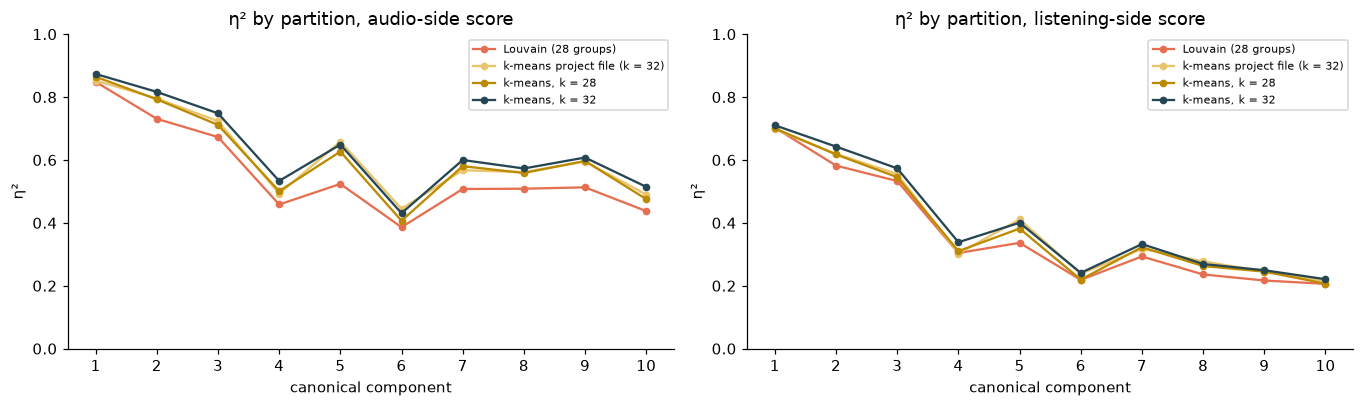

In [4]:
def inv_sqrt(Cm):
    w, Q = np.linalg.eigh(Cm); return (Q / np.sqrt(np.maximum(w, 1e-12))) @ Q.T
def cca_fit(X, Yv, reg=CCA_REG):
    mx, my = X.mean(0), Yv.mean(0); Xc, Yc = X - mx, Yv - my; n_ = len(X)
    Cxx, Cyy, Cxy = Xc.T @ Xc / n_, Yc.T @ Yc / n_, Xc.T @ Yc / n_
    Cxx = Cxx + reg * np.trace(Cxx) / len(Cxx) * np.eye(len(Cxx)); Cyy = Cyy + reg * np.trace(Cyy) / len(Cyy) * np.eye(len(Cyy))
    Wx, Wy = inv_sqrt(Cxx), inv_sqrt(Cyy); U, s, Vt = np.linalg.svd(Wx @ Cxy @ Wy, full_matrices=False)
    return dict(mx=mx, my=my, A=Wx @ U, B=Wy @ Vt.T)
def eta2(score, lab):
    mu = score.mean(); tot = ((score - mu) ** 2).sum()
    return sum(((lab == c).sum() * (score[lab == c].mean() - mu) ** 2) for c in np.unique(lab)) / tot

perm = rng.permutation(len(common)); n_te = int(TEST_FRAC * len(common)); te, tr = perm[:n_te], perm[n_te:]
m = cca_fit(Xa[tr], Yo[tr]); a_te, b_te = (Xa[te] - m["mx"]) @ m["A"], (Yo[te] - m["my"]) @ m["B"]
rho = [np.corrcoef(a_te[:, j], b_te[:, j])[0, 1] for j in range(NC)]
rows = []
for name, runs in PARTS.items():
    for j in range(NC):
        rows.append(dict(partition=name, component=j + 1, rho=rho[j], eta2_audio=np.mean([eta2(a_te[:, j], lab[te]) for lab in runs]), eta2_listening=np.mean([eta2(b_te[:, j], lab[te]) for lab in runs])))
eta = pd.DataFrame(rows)
print("held-out canonical correlations of the first 10 components:", np.round(rho, 3))
print("\nη² of the audio-side score (share of variance between groups):"); print(eta.pivot(index="component", columns="partition", values="eta2_audio")[list(PARTS)].to_string(float_format=lambda x: f"{x:.2f}"))
print("\nη² of the listening-side score:"); print(eta.pivot(index="component", columns="partition", values="eta2_listening")[list(PARTS)].to_string(float_format=lambda x: f"{x:.2f}"))
print("\nmean over the 10 components:"); print(eta.groupby("partition", sort=False)[["eta2_audio", "eta2_listening"]].mean().to_string(float_format=lambda x: f"{x:.3f}"))
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.8))
for a_, col, t in [(ax[0], "eta2_audio", "audio-side score"), (ax[1], "eta2_listening", "listening-side score")]:
    for name in PARTS:
        d = eta[eta.partition == name]; a_.plot(d.component, d[col], "o-", color=PCOL[name], label=name, ms=4)
    a_.set(title=f"η² by partition, {t}", xlabel="canonical component", ylabel="η²", ylim=(0, 1)); a_.set_xticks(range(1, NC + 1)); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 3.1 Reading the shared directions

The canonical correlations on held-out tracks are the same as in `RQ4_extension/02` (0.88, 0.88, 0.85, ...), since they do not involve any partition.
**The strongest shared direction separates Louvain groups as well as pseudo-genres** (η² 0.85 on the audio side and 0.70 on the listening side for both). Over the 10 strongest directions the k-means partitions explain a little more (mean η² 0.61 audio and 0.38 listening at k = 28, against 0.56 and 0.36 for Louvain). The difference comes mostly from components 2, 3 and 5.

**How to read it.** η² is a between-group share of variance around group means, again a centre-based criterion. k-means is built from the largest axes of the audio embedding, and the shared directions are by construction such axes, so a small advantage for k-means is expected. The main point is that the shared sound-listening structure lines up with *both* partitions to a similar degree.

## 4. Partitions found from listening
**What we do.** We partition the tracks using **only their listening vectors**, in two ways:
- spherical k-means on the listening vectors (k = number of Louvain groups and k = 32, three starts), as in `RQ4_extension/02`;
- Louvain on a 20-nearest-neighbour graph of the listening vectors (Peter's pipeline without the PCA step, since the listening vectors have only 64 dimensions; three seeds).

Then we ask which **sound** partition is closer to each **listening** partition (ARI and NMI). The yardsticks are each partition's agreement with itself across seeds.
If the Louvain sound groups are closer to listening partitions than the k-means pseudo-genres are (or the reverse), that says which sound grouping matches behaviour better.

listening Louvain: [32, 36, 34] groups, Q [np.float64(0.763), np.float64(0.761), np.float64(0.765)] (72 s)
agreement of each partition with itself across seeds (ARI): {'Louvain (28 groups)': np.float64(0.816), 'k-means, k = 28': np.float64(0.62), 'k-means, k = 32': np.float64(0.694), 'listening k-means, k = 28': np.float64(0.61), 'listening k-means, k = 32': np.float64(0.568), 'listening Louvain (kNN graph)': np.float64(0.671)}



ARI:
listening_partition            listening Louvain (kNN graph)  listening k-means, k = 28  listening k-means, k = 32
sound_partition                                                                                                   
Louvain (28 groups)                                    0.238                      0.206                      0.197
k-means project file (k = 32)                          0.227                      0.205                      0.189
k-means, k = 28                                        0.233                      0.202                      0.189
k-means, k = 32                                        0.239                      0.219                      0.204

NMI:
listening_partition            listening Louvain (kNN graph)  listening k-means, k = 28  listening k-means, k = 32
sound_partition                                                                                                   
Louvain (28 groups)                                    0.409        

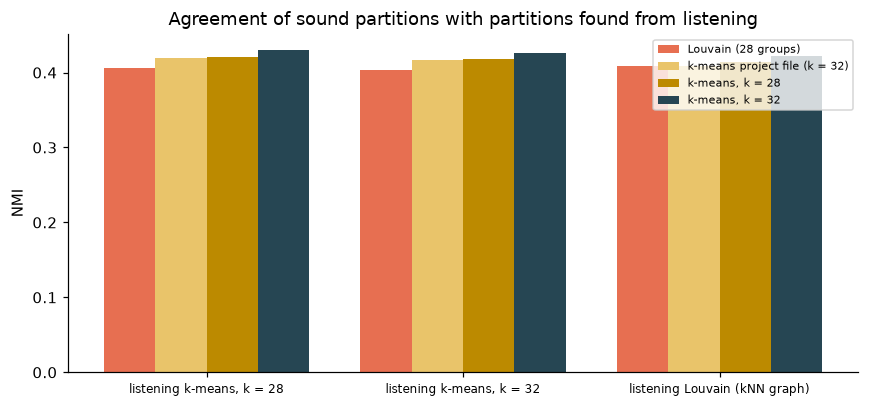

In [5]:
t0 = time.time()
Yo32 = Yo.astype(np.float32)
LP = {f"listening k-means, k = {K_MATCH}": [spherical_kmeans(Yo32, K_MATCH, SEED + 100 * s)[1] for s in range(N_SEEDS)],
      "listening k-means, k = 32": [spherical_kmeans(Yo32, 32, SEED + 100 * s)[1] for s in range(N_SEEDS)]}
idx_l, sims_l = LV.knn_cosine(Yo, K_LISTEN_NN)
lv_runs = [LV.cluster_from_knn(idx_l, sims_l, K_LISTEN_NN, 1.0, s) for s in range(N_SEEDS)]
LP["listening Louvain (kNN graph)"] = [r_.labels for r_ in lv_runs]
print(f"listening Louvain: {[r_.n_clusters for r_ in lv_runs]} groups, Q {[round(r_.modularity, 3) for r_ in lv_runs]} ({time.time() - t0:.0f} s)")
self_ari = {n: np.mean([ari(a, b) for a, b in combinations(r, 2)]) for n, r in {**PARTS, **LP}.items() if len(r) > 1}
print("agreement of each partition with itself across seeds (ARI):", {n: round(v, 3) for n, v in self_ari.items()})
rows = []
for ln, lruns in LP.items():
    for sn, sruns in PARTS.items():
        rows.append(dict(listening_partition=ln, sound_partition=sn, ARI=np.mean([ari(a, b) for a in lruns for b in sruns]), NMI=np.mean([nmi(a, b) for a in lruns for b in sruns])))
cross = pd.DataFrame(rows)
print("\nARI:"); print(cross.pivot(index="sound_partition", columns="listening_partition", values="ARI").loc[list(PARTS)].to_string(float_format=lambda x: f"{x:.3f}"))
print("\nNMI:"); print(cross.pivot(index="sound_partition", columns="listening_partition", values="NMI").loc[list(PARTS)].to_string(float_format=lambda x: f"{x:.3f}"))
fig, ax = plt.subplots(figsize=(8, 3.8)); w = 0.2
for j, sn in enumerate(PARTS):
    d = cross[cross.sound_partition == sn]; ax.bar(np.arange(len(LP)) + (j - 1.5) * w, d.NMI, w, color=PCOL[sn], label=sn)
ax.set_xticks(range(len(LP))); ax.set_xticklabels(list(LP), fontsize=8); ax.set(title="Agreement of sound partitions with partitions found from listening", ylabel="NMI"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 4.1 Reading the partitions found from listening

- **Louvain on the listening vectors** finds 32 to 36 groups (modularity 0.76) and agrees with itself across seeds at ARI 0.67, more than listening k-means does (0.57 to 0.61). The same pattern holds in sound, where Louvain was more reproducible than k-means.
- **Both sound partitions agree with the listening partitions to the same degree.** NMI is 0.40 to 0.41 for Louvain and 0.41 to 0.43 for k-means. ARI is 0.20 to 0.24 for all of them. The largest difference between sound partitions in any column is 0.03 in NMI and 0.02 in ARI.
- So grouping tracks by listening gives a partition that overlaps with sound groups well above chance but differs from them a lot (as `RQ4_extension/02` found for k-means), and **this does not depend on which algorithm made the sound groups.** Neither sound partition is clearly "closer to behaviour".

## 5. Organic versus recommended listening
`RQ4_extension/02` found that with equal training data, recommended-stream listening follows sound more closely than organic listening (cohesion lift 0.44 against 0.29 at k = 32, same-artist/album pairs excluded).
Here we repeat the cohesion comparison for every sound partition, and the agreement with listening Louvain communities found separately in each stream.

In [6]:
rows = []
for stream in ["organic", "recommended"]:
    Yu = Y[stream]
    il, sl = LV.knn_cosine(Yu, K_LISTEN_NN); lvs = [LV.cluster_from_knn(il, sl, K_LISTEN_NN, 1.0, s).labels for s in range(N_SEEDS)]
    for name, runs in PARTS.items():
        rows.append(dict(stream=stream, partition=name, cohesion_lift=np.mean([cohesion(Yu, lab, "artist or album")[0] for lab in runs]),
                         NMI_with_listening_Louvain=np.mean([nmi(a, b) for a in lvs for b in runs])))
str_tab = pd.DataFrame(rows)
for col in ["cohesion_lift", "NMI_with_listening_Louvain"]:
    print(f"\n{col}:"); print(str_tab.pivot(index="partition", columns="stream", values=col).loc[list(PARTS)].assign(difference=lambda d: d.recommended - d.organic).to_string(float_format=lambda x: f"{x:.3f}"))
coh.to_csv(OUT / "listening_space_cohesion.csv", index=False); cross.to_csv(OUT / "listening_space_partition_agreement.csv", index=False); str_tab.to_csv(OUT / "listening_space_streams.csv", index=False)
print("\nwrote RQ4_pipeline/listening_space_cohesion.csv, listening_space_partition_agreement.csv, listening_space_streams.csv")


cohesion_lift:
stream                         organic  recommended  difference
partition                                                      
Louvain (28 groups)              0.268        0.411       0.143
k-means project file (k = 32)    0.285        0.443       0.158
k-means, k = 28                  0.281        0.436       0.155
k-means, k = 32                  0.294        0.454       0.159

NMI_with_listening_Louvain:
stream                         organic  recommended  difference
partition                                                      
Louvain (28 groups)              0.409        0.460       0.051
k-means project file (k = 32)    0.409        0.471       0.062
k-means, k = 28                  0.414        0.471       0.056
k-means, k = 32                  0.422        0.471       0.049

wrote RQ4_pipeline/listening_space_cohesion.csv, listening_space_partition_agreement.csv, listening_space_streams.csv


### 5.1 Reading organic versus recommended

**The stream difference of `RQ4_extension/02` holds for every sound partition.** With same-artist/album pairs excluded, recommended-stream listening is more cohesive within groups than organic listening for Louvain groups (0.411 against 0.268, +0.14) as for k-means (0.436 against 0.281 at k = 28, +0.16; 0.443 against 0.285 for the project file).
Recommended-stream listening communities also agree more with every sound partition (NMI +0.05 to +0.06). So recommended sessions follow sound more closely than organic ones whichever algorithm defines the sound groups. As before, this is an association whose cause is untested.

## 6. Summary and limitations
**What this adds to RQ4.**
1. **The behavioural support for the pseudo-genres does not depend on k-means.** Louvain groups are cohesive in listening space (lift 0.27 against about 0 for shuffled labels; all 28 groups positive), the strongest shared sound-listening direction separates them as well as it separates pseudo-genres (η² 0.85 / 0.70), and partitions found from listening alone agree with them as much as with the pseudo-genres (NMI about 0.41).
2. **On these centre-based measures k-means is slightly ahead** (cohesion 0.28 against 0.27 at 28 groups; mean η² 0.61 against 0.56). This matches notebook 01, where k-means had tighter groups around a centre and Louvain had higher modularity and artist purity. The differences are small next to the effects themselves.
3. **The organic/recommended difference holds with Louvain groups** (recommended more cohesive by 0.14, k-means 0.16).

**Limitations.**
- *Tracks.* The 19,962 tracks with listening vectors in both streams are popular tracks; 99% of them are Louvain graph tracks, so the neighbour vote plays no role here.
- *Fixed listening embeddings* from `RQ4_extension/02` (item2vec, settings not tuned, 4.3 million training tokens per stream).
- *Centre-based measures.* Cohesion and η² favour compact groups. A graph-based view of the same question is notebook 02 (modularity on the co-listening graph).
- *Associations only*, in Yambda-50M.